In [2]:
!pip install -q qiskit qiskit-aer networkx matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00


In [3]:
import itertools, numpy as np, networkx as nx
import matplotlib.pyplot as plt

# ESP32 nodes; weight = interference strength
edges = [(0,1,3),(0,2,2),(1,2,4),(1,3,1),
         (2,4,2),(3,4,3),(3,5,2),(4,5,4)]
n = 6
G = nx.Graph()
G.add_weighted_edges_from(edges)
W = sum(w for _,_,w in edges)

def cut_value(bits):  # bits[i] = channel of node i
    return sum(w for i,j,w in edges if bits[i] != bits[j])

best_classical, best_bits = max(
    ((cut_value(b), b) for b in itertools.product([0,1], repeat=n)))
print("Brute-force optimal cut:", best_classical, best_bits)

Brute-force optimal cut: 17 (1, 0, 1, 1, 0, 1)


In [4]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

p = 2
params = ParameterVector("t", 2*p)

H = SparsePauliOp.from_sparse_list(
    [("ZZ", [i,j], w/2) for i,j,w in edges], num_qubits=n)

qc = QuantumCircuit(n)
qc.h(range(n))
for k in range(p):
    gamma, beta = params[2*k], params[2*k+1]
    for i,j,w in edges:
        qc.rzz(gamma*w, i, j)
    qc.rx(2*beta, range(n))

def energy(x):
    sv = Statevector(qc.assign_parameters(x))
    return sv.expectation_value(H).real

history, best = [], None
rng = np.random.default_rng(1)
for _ in range(8):  # random restarts
    x0 = rng.uniform(0, np.pi, 2*p)
    res = minimize(energy, x0, method="COBYLA",
                   callback=lambda xk: history.append(energy(xk)))
    if best is None or res.fun < best.fun:
        best = res

exp_cut = W/2 - best.fun
print("QAOA expected cut:", round(exp_cut,3))
print("Approximation ratio:", round(exp_cut/best_classical,3))

QAOA expected cut: 14.104
Approximation ratio: 0.83


Most likely channels: [0, 1, 0, 0, 1, 0] cut = 17 prob = 0.062


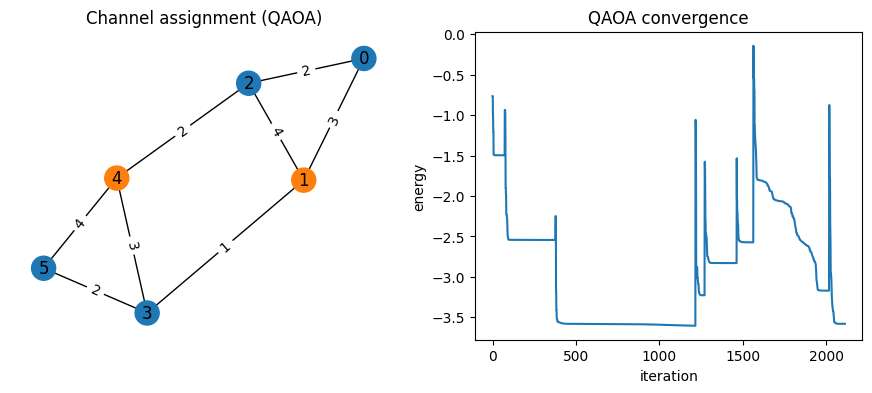

In [5]:
probs = Statevector(qc.assign_parameters(best.x)).probabilities_dict()
top = max(probs, key=probs.get)
bits = [int(c) for c in top[::-1]]  # Qiskit is little-endian
print("Most likely channels:", bits, "cut =", cut_value(bits),
      "prob =", round(probs[top],3))

fig, ax = plt.subplots(1,2, figsize=(11,4))
pos = nx.spring_layout(G, seed=3)
nx.draw(G, pos, ax=ax[0], with_labels=True,
        node_color=["tab:blue" if b==0 else "tab:orange" for b in bits])
nx.draw_networkx_edge_labels(G, pos, ax=ax[0],
        edge_labels=nx.get_edge_attributes(G,"weight"))
ax[0].set_title("Channel assignment (QAOA)")
ax[1].plot(history); ax[1].set_title("QAOA convergence")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("energy")
plt.show()

Optimal (brute force): 17
Random assignment (avg): 10.58  ratio 0.62
Greedy heuristic: 17  ratio 1.00
QAOA p=1: expected cut 14.08, ratio 0.828, P(optimal) 0.115
QAOA p=2: expected cut 13.76, ratio 0.810, P(optimal) 0.065
QAOA p=3: expected cut 14.10, ratio 0.829, P(optimal) 0.106


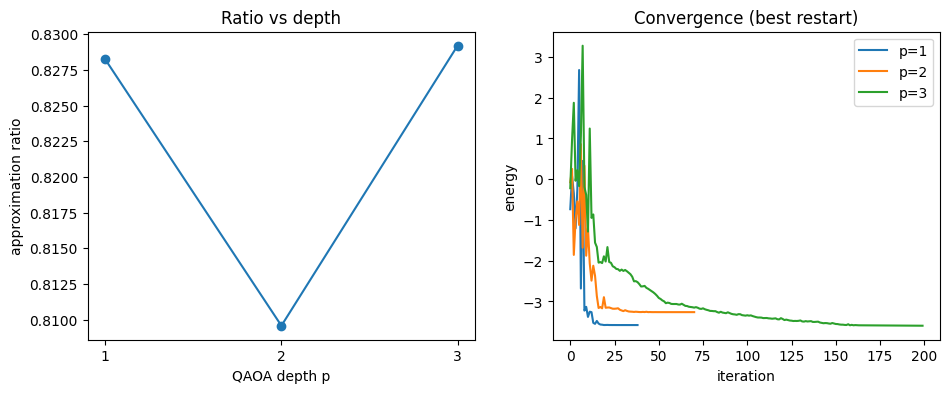

In [6]:
rng = np.random.default_rng(7)

def build(p):
    th = ParameterVector("t", 2*p)
    qc = QuantumCircuit(n); qc.h(range(n))
    for k in range(p):
        for i,j,w in edges: qc.rzz(th[2*k]*w, i, j)
        qc.rx(2*th[2*k+1], range(n))
    return qc

def run(p, restarts=6):
    qc, best, best_vals = build(p), None, None
    for _ in range(restarts):
        vals = []
        def f(x):
            v = Statevector(qc.assign_parameters(x)).expectation_value(H).real
            vals.append(v); return v
        res = minimize(f, rng.uniform(0, np.pi, 2*p),
                       method="COBYLA", options={"maxiter": 200})
        if best is None or res.fun < best.fun:
            best, best_vals = res, vals
    return qc, best, best_vals

def p_optimal(qc, x):
    probs = Statevector(qc.assign_parameters(x)).probabilities_dict()
    return sum(pr for s, pr in probs.items()
               if cut_value([int(c) for c in s[::-1]]) == best_classical)

# classical baselines
rand_cut = np.mean([cut_value(rng.integers(0, 2, n)) for _ in range(2000)])
side = {}
for v in range(n):  # greedy: put each node opposite its heavier neighbours
    gain0 = sum(w for i,j,w in edges if (i==v and side.get(j)==1) or (j==v and side.get(i)==1))
    gain1 = sum(w for i,j,w in edges if (i==v and side.get(j)==0) or (j==v and side.get(i)==0))
    side[v] = 0 if gain0 >= gain1 else 1
greedy_cut = cut_value([side[i] for i in range(n)])

print(f"Optimal (brute force): {best_classical}")
print(f"Random assignment (avg): {rand_cut:.2f}  ratio {rand_cut/best_classical:.2f}")
print(f"Greedy heuristic: {greedy_cut}  ratio {greedy_cut/best_classical:.2f}")

ratios, curves = [], {}
for p in [1, 2, 3]:
    qc_p, b, vals = run(p)
    r = (W/2 - b.fun) / best_classical
    ratios.append(r); curves[p] = vals
    print(f"QAOA p={p}: expected cut {W/2-b.fun:.2f}, ratio {r:.3f}, "
          f"P(optimal) {p_optimal(qc_p, b.x):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([1,2,3], ratios, "o-"); ax[0].set_xticks([1,2,3])
ax[0].set_xlabel("QAOA depth p"); ax[0].set_ylabel("approximation ratio")
ax[0].set_title("Ratio vs depth")
for p, v in curves.items(): ax[1].plot(v, label=f"p={p}")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("energy")
ax[1].set_title("Convergence (best restart)"); ax[1].legend()
plt.show()

/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


p=1: [0.765, 0.764, 0.763, 0.757, 0.743]
p=3: [0.889, 0.873, 0.849, 0.816, 0.757]


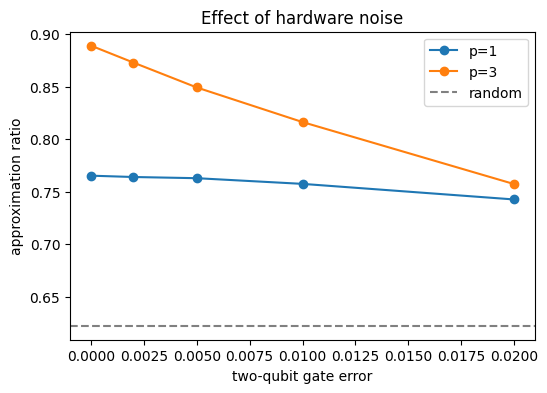

In [7]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import transpile

def exp_cut_from_counts(counts):
    tot = sum(counts.values())
    return sum(cnt * cut_value([int(c) for c in s[::-1]])
               for s, cnt in counts.items()) / tot

errs = [0, 0.002, 0.005, 0.01, 0.02]   # two-qubit gate error rates
noise_results = {}
for p in [1, 3]:
    qc_p, b, _ = run(p, restarts=4)      # optimise once, noise-free
    circ = qc_p.assign_parameters(b.x)
    circ.measure_all()
    out = []
    for e in errs:
        nm = NoiseModel()
        nm.add_all_qubit_quantum_error(depolarizing_error(e/10, 1), ["rz", "sx", "x"])
        nm.add_all_qubit_quantum_error(depolarizing_error(e, 2), ["cx"])
        sim = AerSimulator(noise_model=nm)
        t = transpile(circ, sim, basis_gates=["rz", "sx", "x", "cx"],
                      optimization_level=1)
        counts = sim.run(t, shots=8000).result().get_counts()
        out.append(exp_cut_from_counts(counts) / best_classical)
    noise_results[p] = out
    print(f"p={p}:", [round(v, 3) for v in out])

plt.figure(figsize=(6, 4))
for p, v in noise_results.items():
    plt.plot(errs, v, "o-", label=f"p={p}")
plt.axhline(rand_cut / best_classical, ls="--", c="gray", label="random")
plt.xlabel("two-qubit gate error"); plt.ylabel("approximation ratio")
plt.title("Effect of hardware noise"); plt.legend(); plt.show()